# Required SNR versus chromatic dispersion

Fig. 3 of the OFC 2027 paper *End-to-End Optimization of Direct-Detection Optical Systems*: SNR (Es/N0)
required for BER 1e-3 versus the chromatic dispersion index γ = −2β₂R_b²L of Secondini et al. (JLT 2020),
R_b being the bit rate, for the methods and configurations of `ofc_e2e.ipynb`: linear FFE, RX-only NN,
E2E-NN and E2E-LUT-DT, in the thermal-noise regime with PAM-4 and in the ASE-noise regime with BPAM-4,
with TX filter bandwidths 0.5 and 0.25 R_s.

The fiber length sets γ (0.69 at 10 km and 40 Gbps). Every length is a separate configuration, with its
own digital surrogate and training, cached in `results/ofc_e2e/` like the configurations of
`ofc_e2e.ipynb`; the 10-km configurations are those of Fig. 2 and are shared with that notebook,
decision trees included. The knobs are those of `ofc_e2e.ipynb`, except the list of fiber lengths.

## 1. Setup and knobs

In [3]:
# Resolve paths independently of the notebook's working directory.
from pathlib import Path
import os
import sys
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "functions" / "link.py").is_file())
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

%load_ext autoreload
%autoreload 2

from dataclasses import replace
import math
import shutil
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import Markdown, display

from functions.decision_tree import complexity, decision_trees
from functions.evaluation import threshold
from functions.parameters import Budget, Case, LinkParameters, EVALUATION_LEVEL_DB
from functions.pipeline import case_folder, run_case, training_folder

%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# ---------------- knobs (as in ofc_e2e.ipynb, except the fiber lengths) ----------------
REGIMES          = ["electrical", "optical"]   # noise: "electrical" (thermal) and/or "optical" (ASE)
FORMAT           = {"electrical": "pam4", "optical": "bpam"}
TX_BANDWIDTH_GHZ = [10, 5]                     # TX filter 3-dB bandwidth: 0.5 and 0.25 Rs at 20 GBd
TX_PULSE         = "nrz"                       # "nrz" or "rrc"
TX_FILTER        = "gaussian"                  # H_TX, analog after the DAC: "gaussian", "rectangular" or "none"
OPTICAL_FILTER   = {"electrical": "none", "optical": "supergaussian"}   # H_opt per noise regime
OPTICAL_FILTER_GHZ = 30                        # full 3-dB width of the super-Gaussian H_opt: 1.5 Rs at 20 GBd
SUPERGAUSSIAN_ORDER = 4
RX_FILTER        = "gaussian"                  # H_RX: "gaussian" or "none"
RX_FILTER_GHZ    = 10
RX_FILTER_BEFORE_ADC = True                    # True: analog H_RX before the ADC, refitted by the digital surrogate
DAC_BITS         = 6                           # None: ideal converter
ADC_BITS         = 6
FIBER_KM         = [0., 5., 10., 15., 20., 25., 29.1824]   # fiber lengths: gamma from 0 to 2.03 at 40 Gbps
FIG2_KM          = 10.                         # the fiber length of Fig. 2: its configurations (labels without the
                                               # length) and decision trees are shared with ofc_e2e.ipynb
BETA2_PS2_PER_KM = -21.7                       # C-band standard single-mode fiber
MZM_BIAS         = "null"
ANALOG_SPS       = 2                           # samples per symbol of the analog simulation
RX_SPS           = {"electrical": 1, "optical": 2}   # ADC and RX DSP samples per symbol
POWER_REFERENCE  = "mean"                      # Secondini's: every TX at unit mean optical power
PRECODE          = True                        # differential precoding of the BPAM sign bit
TRAINING_LEVEL_DB = {"electrical": 18.92, "optical": 16.05}   # SNR or OSNR during training
METHODS          = ["linear", "rx_only", "e2e"]
SURROGATE_STEPS  = 40_000                      # digital-surrogate fit
RX_STEPS         = 100_000                     # RX initialization with the conventional TX
TX_STEPS         = 8_000                       # TX NN fitted to the conventional voltages
E2E_STEPS        = 300_000                     # TX NN and RX NN trained jointly
RX_ONLY_STEPS    = 300_000                     # RX-only reference, continued from the RX initialization
EVAL_BLOCKS      = 128                         # held-out blocks of 32768 symbols per level, at least
SEED             = 0
LABEL            = {"electrical": "htx_surrogate{length}_mean_rx1sps_300k", "optical": "htx_surrogate{length}_300k"}
                                               # {length}: "" at FIG2_KM, "_<km>km" otherwise; part of the cache key
FORCE_RETRAIN    = False                       # True: delete and recompute every configuration, those of Fig. 2 too
TREE_LEAVES      = 1024                        # RX decision trees: leaves per tree (2047 nodes); None: no trees
TREE_STRUCTURE   = None                        # "symbol", "bit" or None, as the RX NNs
TREE_SOURCE      = "surrogate"                 # training windows of the trees: "surrogate" or "simulator"
SNR_RANGE_DB     = (13, 22)                    # SNR axis of Fig. 2: test levels of the trees at FIG2_KM
REQUIRED_SNR_DB  = (15, 26)                    # y axis of the figure

WORK = PROJECT_ROOT / "results" / "ofc_e2e"
BUDGET = Budget(surrogate_steps=SURROGATE_STEPS, rx_steps=RX_STEPS, tx_steps=TX_STEPS, joint_steps=E2E_STEPS,
                rx_only_steps=RX_ONLY_STEPS, eval_blocks=EVAL_BLOCKS)
LINKS = {regime: LinkParameters(tx_pulse=TX_PULSE, tx_filter=TX_FILTER, optical_filter=OPTICAL_FILTER[regime],
                                optical_gaussian_bandwidth=OPTICAL_FILTER_GHZ * 1e9,
                                optical_supergaussian_order=SUPERGAUSSIAN_ORDER, rx_filter=RX_FILTER,
                                rx_filter_bandwidth=RX_FILTER_GHZ * 1e9, rx_filter_before_adc=RX_FILTER_BEFORE_ADC,
                                dac_bits=DAC_BITS, adc_bits=ADC_BITS, fiber_length_km=FIG2_KM,
                                beta2_ps2_per_km=BETA2_PS2_PER_KM, analog_sps=ANALOG_SPS,
                                power_reference=POWER_REFERENCE, mzm_bias=MZM_BIAS,
                                rx_sps=None if RX_SPS[regime] == 2 else RX_SPS[regime])   # None: as the DSP
         for regime in ("electrical", "optical")}
RS_GHZ = LINKS["optical"].symbol_rate / 1e9    # symbol rate in GBd, for the normalized bandwidths
# ASE: Es/N0 = OSNR + 10 log10(2 B_ref / R_s), with B_ref = 12.5 GHz and two polarizations (0.97 dB at 20 GBd)
SHIFT = {"electrical": 0., "optical": 10 * np.log10(2 * LINKS["optical"].osnr_reference_bandwidth
                                                    / LINKS["optical"].symbol_rate)}


def gamma(km):
    """Chromatic dispersion index -2 beta2 Rb^2 L of Secondini et al. (JLT 2020), Rb the bit rate."""
    p = LINKS["optical"]
    return -2 * p.beta2_ps2_per_km * 1e-27 * (p.bits_per_symbol * p.symbol_rate) ** 2 * km * 1e3


def make_case(regime, tx_bandwidth_ghz, km):
    length = "" if km == FIG2_KM else f"_{km:g}km"
    return Case(regime=regime, fmt=FORMAT[regime], tx_bandwidth_ghz=float(tx_bandwidth_ghz), precode=PRECODE,
                training_level_db=TRAINING_LEVEL_DB[regime], link=replace(LINKS[regime], fiber_length_km=float(km)),
                seed=SEED, label=LABEL[regime].format(length=length))


CASES = [make_case(r, b, km) for r in REGIMES for b in TX_BANDWIDTH_GHZ for km in FIBER_KM]
print(f"{len(CASES)} configurations; results in {WORK}")
for km in FIBER_KM:   # gamma scales with beta2 Rb^2 L: the same gamma at 100 Gbps over (40/100)^2 times the length
    print(f"  {km:8g} km: gamma = {gamma(km):.2f}; at 100 Gbps, {km * .16:5.2f} km in the C-band or "
          f"{km * .16 * abs(BETA2_PS2_PER_KM):5.1f} km in the O-band (beta2 = -1 ps^2/km)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cuda
28 configurations; results in c:\Users\celli\Documents\MLforCPO2\results\ofc_e2e
         0 km: gamma = 0.00; at 100 Gbps,  0.00 km in the C-band or   0.0 km in the O-band (beta2 = -1 ps^2/km)
         5 km: gamma = 0.35; at 100 Gbps,  0.80 km in the C-band or  17.4 km in the O-band (beta2 = -1 ps^2/km)
        10 km: gamma = 0.69; at 100 Gbps,  1.60 km in the C-band or  34.7 km in the O-band (beta2 = -1 ps^2/km)
        15 km: gamma = 1.04; at 100 Gbps,  2.40 km in the C-band or  52.1 km in the O-band (beta2 = -1 ps^2/km)
        20 km: gamma = 1.39; at 100 Gbps,  3.20 km in the C-band or  69.4 km in the O-band (beta2 = -1 ps^2/km)
        25 km: gamma = 1.74; at 100 Gbps,  4.00 km in the C-band or  86.8 km in the O-band (beta2 = -1 ps^2/km)
   29.1824 km: gamma = 2.03; at 100 Gbps,  4.67 km in the C-band or 101.3 km in the O-band (beta2 = -1 ps^2/km)


## 2. Training and evaluation

Every fiber length is a configuration of `ofc_e2e.ipynb`: its own digital surrogate (the dispersion
belongs to the analog link), RX initialization, TX pretraining, joint and RX-only training, linear FFE
fitted at every level, held-out BER on the reference simulator over the standard grid of the regime.
Computed configurations are loaded; a new one takes as long as one of `ofc_e2e.ipynb`.

In [4]:
summaries = {}
for case in CASES:
    if FORCE_RETRAIN:
        for folder in (case_folder(WORK, case, BUDGET, EVALUATION_LEVEL_DB[case.regime]), training_folder(WORK, case, BUDGET)):
            shutil.rmtree(folder, ignore_errors=True)
    summaries[case.name] = run_case(case, WORK, BUDGET, methods=METHODS, device=device)

## 3. RX decision trees

As in `ofc_e2e.ipynb`: one four-class tree per symbol for PAM-4, one tree per bit for BPAM, 1024 leaves,
trained on windows at five levels around the level where the E2E RX NN reaches BER 1e-3 (generated
through the digital surrogate with `TREE_SOURCE = "surrogate"`), tested on the reference simulator.
Test levels: at `FIG2_KM` those of Fig. 2, the integer levels of `SNR_RANGE_DB`, so that the trees are
shared with `ofc_e2e.ipynb`; at the other lengths the integer levels from 2 dB below to 7 dB above the
E2E RX NN level at BER 1e-3, which follow the curves as they move with the dispersion. A configuration
whose E2E RX NN does not reach BER 1e-3 gets no trees.

In [5]:
def tree_levels(case):
    """Test levels of the trees, in the levels of the regime (SNR for thermal noise, OSNR for ASE)."""
    if case.link.fiber_length_km == FIG2_KM:    # as ofc_e2e.ipynb: the integer levels of the Fig. 2 axis
        low, high = SNR_RANGE_DB[0] - SHIFT[case.regime] - .2, SNR_RANGE_DB[1] - SHIFT[case.regime] + .2
        return [float(l) for l in range(math.ceil(low), math.floor(high) + 1)]
    nn = threshold(summaries[case.name]["results"]["e2e"]["points"]["reference"])["level_db"]
    return [float(l) for l in range(math.floor(nn) - 2, math.ceil(nn) + 8)]


trees = {}
if TREE_LEAVES:
    rows = ["| Configuration | γ | Nodes | Average depth | Comparisons per bit | Memory per bit |",
            "|---|---:|---:|---:|---:|---:|"]
    for case in CASES:
        if threshold(summaries[case.name]["results"]["e2e"]["points"]["reference"]) is None:
            print(f"{case.name}: the E2E RX NN does not reach BER 1e-3, no trees")
            continue
        t = trees[case.name] = decision_trees(case, WORK, BUDGET, tree_levels(case), TREE_STRUCTURE, TREE_LEAVES,
                                              source=TREE_SOURCE, device=device, verbose=False)
        c = complexity(t)
        rows.append(f"| {case.name} | {gamma(case.link.fiber_length_km):.2f} | {'/'.join(map(str, c['nodes']))} | "
                    f"{'/'.join(f'{d:.1f}' for d in c['average_depth'])} | {c['comparisons_per_bit']:.1f} | "
                    f"{c['memory_kbit_per_bit']:.1f} kbit |")
    display(Markdown("\n".join(rows) + "\n\nPer-tree values separated by /; average depth at the test level closest "
                     "to BER 1e-3."))

| Configuration | γ | Nodes | Average depth | Comparisons per bit | Memory per bit |
|---|---:|---:|---:|---:|---:|
| electrical_pam4_bw10_htx_surrogate_0km_mean_rx1sps_300k | 0.00 | 2047 | 7.9 | 4.0 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_5km_mean_rx1sps_300k | 0.35 | 2047 | 8.2 | 4.1 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_mean_rx1sps_300k | 0.69 | 2047 | 8.3 | 4.1 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_15km_mean_rx1sps_300k | 1.04 | 2047 | 9.3 | 4.6 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_20km_mean_rx1sps_300k | 1.39 | 2047 | 9.7 | 4.8 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_25km_mean_rx1sps_300k | 1.74 | 2047 | 9.5 | 4.7 | 6.1 kbit |
| electrical_pam4_bw10_htx_surrogate_29.1824km_mean_rx1sps_300k | 2.03 | 2047 | 8.3 | 4.2 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_0km_mean_rx1sps_300k | 0.00 | 2047 | 8.4 | 4.2 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_5km_mean_rx1sps_300k | 0.35 | 2047 | 8.4 | 4.2 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_mean_rx1sps_300k | 0.69 | 2047 | 8.3 | 4.2 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_15km_mean_rx1sps_300k | 1.04 | 2047 | 8.6 | 4.3 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_20km_mean_rx1sps_300k | 1.39 | 2047 | 8.1 | 4.1 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_25km_mean_rx1sps_300k | 1.74 | 2047 | 8.0 | 4.0 | 6.1 kbit |
| electrical_pam4_bw5_htx_surrogate_29.1824km_mean_rx1sps_300k | 2.03 | 2047 | 8.1 | 4.0 | 6.1 kbit |
| optical_bpam_bw10_htx_surrogate_0km_300k | 0.00 | 2047/2047 | 6.9/7.0 | 7.0 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_5km_300k | 0.35 | 2047/2047 | 6.9/7.0 | 7.0 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_300k | 0.69 | 2047/2047 | 6.7/6.6 | 6.7 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_15km_300k | 1.04 | 2047/2047 | 6.9/7.0 | 6.9 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_20km_300k | 1.39 | 2047/2047 | 6.4/7.2 | 6.8 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_25km_300k | 1.74 | 2047/2047 | 6.4/7.6 | 7.0 | 12.3 kbit |
| optical_bpam_bw10_htx_surrogate_29.1824km_300k | 2.03 | 2047/2047 | 6.7/7.5 | 7.1 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_0km_300k | 0.00 | 2047/2047 | 7.5/7.8 | 7.6 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_5km_300k | 0.35 | 2047/2047 | 7.3/7.7 | 7.5 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_300k | 0.69 | 2047/2047 | 6.9/7.9 | 7.4 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_15km_300k | 1.04 | 2047/2047 | 6.9/7.5 | 7.2 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_20km_300k | 1.39 | 2047/2047 | 6.6/7.9 | 7.3 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_25km_300k | 1.74 | 2047/2047 | 6.7/7.4 | 7.1 | 12.3 kbit |
| optical_bpam_bw5_htx_surrogate_29.1824km_300k | 2.03 | 2047/2047 | 6.5/7.6 | 7.0 | 12.3 kbit |

Per-tree values separated by /; average depth at the test level closest to BER 1e-3.

## 4. Required SNR at BER 1e-3

Log-linear interpolation between the two levels that bracket BER 1e-3, as SNR Es/N0 (the OSNR plus
0.97 dB for ASE); "–": BER 1e-3 not reached on the levels counted. The last row of each table is the
gain of E2E-NN over the RX-only NN.

In [6]:
STYLE = {"linear": ("linear FFE", "s", "k"), "rx_only": ("RX-only NN", "o", "b"),       # name, marker, colour
         "e2e": ("E2E-NN", "D", "r"), "trees": ("E2E-LUT-DT", "^", "g")}
FORMAT_NAME = {"pam4": "PAM-4", "bpam": "BPAM-4"}
FIGURE_METHODS = METHODS + (["trees"] if trees else [])


def required_snr(case, method):
    """SNR (Es/N0, dB) at BER 1e-3 on the reference simulator, None if not reached."""
    if method == "trees":
        level = trees[case.name]["level_db"] if case.name in trees else None
    else:
        t = threshold(summaries[case.name]["results"][method]["points"]["reference"])
        level = None if t is None else t["level_db"]
    return None if level is None else level + SHIFT[case.regime]


snr = {(r, b, km, m): required_snr(make_case(r, b, km), m)
       for r in REGIMES for b in TX_BANDWIDTH_GHZ for km in FIBER_KM for m in FIGURE_METHODS}


def value(v):
    return "–" if v is None else f"{v:.2f}"


for regime in REGIMES:
    for band in TX_BANDWIDTH_GHZ:
        rows = ["| | " + " | ".join(f"γ = {gamma(km):.2f}" for km in FIBER_KM) + " |", "|---|" + "---:|" * len(FIBER_KM)]
        for m in FIGURE_METHODS:
            rows.append(f"| {STYLE[m][0]} | " + " | ".join(value(snr[(regime, band, km, m)]) for km in FIBER_KM) + " |")
        gains = [None if snr[(regime, band, km, "rx_only")] is None or snr[(regime, band, km, "e2e")] is None
                 else snr[(regime, band, km, "rx_only")] - snr[(regime, band, km, "e2e")] for km in FIBER_KM]
        rows.append("| *E2E-NN gain over RX-only NN* | " + " | ".join(value(g) for g in gains) + " |")
        display(Markdown(f"**{regime}, {FORMAT_NAME[FORMAT[regime]]}, B_TX = {band / RS_GHZ:g} R_s** "
                         "(required SNR in dB)\n\n" + "\n".join(rows)))

**electrical, PAM-4, B_TX = 0.5 R_s** (required SNR in dB)

| | γ = 0.00 | γ = 0.35 | γ = 0.69 | γ = 1.04 | γ = 1.39 | γ = 1.74 | γ = 2.03 |
|---|---:|---:|---:|---:|---:|---:|---:|
| linear FFE | 19.99 | 19.96 | 20.17 | 20.71 | 21.73 | 23.99 | – |
| RX-only NN | 18.18 | 18.18 | 18.32 | 18.61 | 19.07 | 19.81 | 20.90 |
| E2E-NN | 16.85 | 16.82 | 16.92 | 16.68 | 16.91 | 17.48 | 18.23 |
| E2E-LUT-DT | 16.81 | 16.74 | 16.87 | 16.74 | 17.15 | 18.35 | 20.13 |
| *E2E-NN gain over RX-only NN* | 1.33 | 1.36 | 1.40 | 1.93 | 2.16 | 2.34 | 2.66 |

**electrical, PAM-4, B_TX = 0.25 R_s** (required SNR in dB)

| | γ = 0.00 | γ = 0.35 | γ = 0.69 | γ = 1.04 | γ = 1.39 | γ = 1.74 | γ = 2.03 |
|---|---:|---:|---:|---:|---:|---:|---:|
| linear FFE | – | – | – | – | – | – | – |
| RX-only NN | 21.76 | 21.72 | 21.96 | 22.32 | 23.00 | 24.38 | – |
| E2E-NN | 17.28 | 17.20 | 17.32 | 17.39 | 17.60 | 18.19 | 18.81 |
| E2E-LUT-DT | 17.32 | 17.44 | 17.50 | 17.81 | 18.26 | 19.43 | 22.54 |
| *E2E-NN gain over RX-only NN* | 4.48 | 4.52 | 4.64 | 4.93 | 5.40 | 6.18 | – |

**optical, BPAM-4, B_TX = 0.5 R_s** (required SNR in dB)

| | γ = 0.00 | γ = 0.35 | γ = 0.69 | γ = 1.04 | γ = 1.39 | γ = 1.74 | γ = 2.03 |
|---|---:|---:|---:|---:|---:|---:|---:|
| linear FFE | 19.63 | 19.83 | 20.66 | 22.75 | – | – | – |
| RX-only NN | 17.59 | 17.65 | 17.80 | 18.06 | 18.52 | 19.21 | 20.16 |
| E2E-NN | 15.18 | 15.45 | 15.98 | 16.72 | 17.06 | 17.15 | 17.44 |
| E2E-LUT-DT | 16.34 | 16.69 | 17.04 | 18.21 | 18.81 | 20.05 | 22.06 |
| *E2E-NN gain over RX-only NN* | 2.41 | 2.20 | 1.81 | 1.34 | 1.46 | 2.06 | 2.72 |

**optical, BPAM-4, B_TX = 0.25 R_s** (required SNR in dB)

| | γ = 0.00 | γ = 0.35 | γ = 0.69 | γ = 1.04 | γ = 1.39 | γ = 1.74 | γ = 2.03 |
|---|---:|---:|---:|---:|---:|---:|---:|
| linear FFE | – | – | – | – | – | – | – |
| RX-only NN | 19.60 | 19.70 | 20.01 | 20.46 | 20.93 | 21.59 | 23.55 |
| E2E-NN | 16.40 | 16.61 | 16.78 | 17.07 | 17.24 | 17.54 | 17.88 |
| E2E-LUT-DT | 18.49 | 18.72 | 18.92 | 19.34 | 20.02 | 21.40 | 23.37 |
| *E2E-NN gain over RX-only NN* | 3.20 | 3.10 | 3.24 | 3.39 | 3.69 | 4.05 | 5.67 |

## 5. Figure

Fig. 3 of the paper: one panel per noise regime, (a) thermal noise and (b) ASE noise. Colour and marker:
method; line style and marker fill: TX filter bandwidth (solid lines and filled markers for the widest
band); the E2E-LUT-DT curves are thinner. Where BER 1e-3 is not reached at the next fiber length, the
curve leaves the plot through the top. Saved as `dispersion_figure.pdf`.

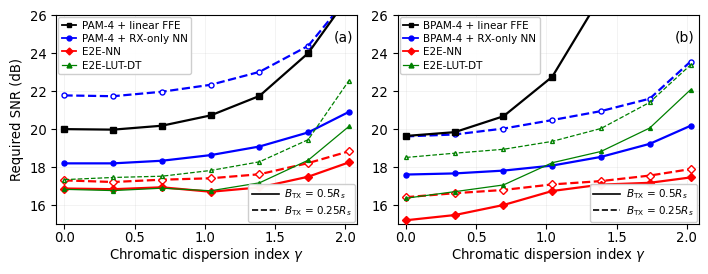

In [7]:
BANDS = sorted(TX_BANDWIDTH_GHZ, reverse=True)
LINE = {b: ("-", "--", "-.", ":")[i % 4] for i, b in enumerate(BANDS)}   # line style per TX filter bandwidth
WIDTH = 1.6                                     # line width of every curve but the trees
FONT, LEGEND_FONT = 9.5, 7.5
FIGURE_HEIGHT = 2.65                            # inches; the width is 3.5 inches per panel

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": FONT, "pdf.fonttype": 42})
fig, axes = plt.subplots(1, len(REGIMES), figsize=(3.5 * len(REGIMES), FIGURE_HEIGHT), sharey=True, squeeze=False)
legend_style = dict(fontsize=LEGEND_FONT, framealpha=.95, labelspacing=.3, borderpad=.35, handletextpad=.5,
                    borderaxespad=.2)
largest = gamma(max(FIBER_KM))
for ax, regime in zip(axes[0], REGIMES):
    for band in BANDS:
        wide = band == BANDS[0]
        for method in FIGURE_METHODS:
            name, marker, colour = STYLE[method]
            points, leaves = [], None
            for km in sorted(FIBER_KM):
                v = snr[(regime, band, km, method)]
                if v is not None:
                    points.append((gamma(km), v))
                elif points and leaves is None:
                    leaves = gamma(km)          # first length where BER 1e-3 is not reached
            if not points:
                continue
            thin = method == "trees"
            style = dict(color=colour, ls=LINE[band], lw=.9 if thin else WIDTH,
                         zorder=(5 if thin else 3) - (0 if wide else 1))
            ax.plot(*zip(*points), marker=marker, markersize=2.8 if thin else 1.2 + 1.5 * WIDTH,
                    markerfacecolor=colour if wide else "white", **style)
            if leaves is not None:              # out of the plot through the top
                ax.plot([points[-1][0], leaves], [points[-1][1], REQUIRED_SNR_DB[1] + 1], **style)
    ax.set_xlim(-.06, largest + .06)
    ax.set_xticks([t / 2 for t in range(int(2 * largest) + 1)])
    ax.set_ylim(*REQUIRED_SNR_DB)
    ax.set_xlabel(r"Chromatic dispersion index $\gamma$")
    ax.text(.985, .93, f"({'ab'[['electrical', 'optical'].index(regime)]})", transform=ax.transAxes,
            ha="right", va="top", fontsize=10)
    ax.tick_params(axis="x", pad=1.5)           # tick labels and axis label close to the axis
    ax.xaxis.labelpad = 1.
    ax.tick_params(labelleft=True)
    ax.grid(alpha=.25, lw=.4)
    fmt = FORMAT_NAME[FORMAT[regime]]
    names = {"linear": f"{fmt} + linear FFE", "rx_only": f"{fmt} + RX-only NN",
             "e2e": STYLE["e2e"][0], "trees": STYLE["trees"][0]}
    methods = ax.legend(handles=[Line2D([], [], color=STYLE[m][2], lw=.9 if m == "trees" else 1.3, marker=STYLE[m][1],
                                        markersize=3.5, label=names[m]) for m in FIGURE_METHODS],
                        loc="upper left", handlelength=1.4, **legend_style)
    ax.add_artist(methods)
    ax.legend(handles=[Line2D([], [], color="black", lw=1.2, ls=LINE[b],
                              label=rf"$B_{{\mathrm{{TX}}}}$ = {b / RS_GHZ:g}$R_s$") for b in BANDS],
              loc="lower right", handlelength=2.6, **legend_style)
axes[0, 0].set_ylabel("Required SNR (dB)")
fig.tight_layout(pad=.4, w_pad=1.0)
fig.savefig(WORK / "dispersion_figure.pdf")
fig.savefig(WORK / "dispersion_figure.png", dpi=220)
plt.show()

## 6. Column files

One file per noise regime: chromatic dispersion index, fiber length, then the required SNR of every
method and TX filter bandwidth (nan: BER 1e-3 not reached).

In [8]:
for regime in REGIMES:
    names = [f"{m}_bw{b:g}" for b in TX_BANDWIDTH_GHZ for m in FIGURE_METHODS]
    table = [[gamma(km), km] + [np.nan if snr[(regime, b, km, m)] is None else snr[(regime, b, km, m)]
                                for b in TX_BANDWIDTH_GHZ for m in FIGURE_METHODS] for km in FIBER_KM]
    path = WORK / f"dispersion_{regime}_{FORMAT[regime]}.txt"
    np.savetxt(path, np.array(table), fmt="%.4f", header="gamma km " + " ".join(names)
               + "\nrequired SNR (Es/N0, dB) at BER 1e-3 on the reference simulator; nan: not reached")
    print("written", path)

written c:\Users\celli\Documents\MLforCPO2\results\ofc_e2e\dispersion_electrical_pam4.txt
written c:\Users\celli\Documents\MLforCPO2\results\ofc_e2e\dispersion_optical_bpam.txt
